# Task 3: Data Cleaning

## Objective

The objective of this task is to clean and prepare a housing dataset for further analysis.

The dataset will be examined for missing values, duplicate records, inconsistent categorical values, incorrect data types, invalid numerical values, and potential outliers.

The final output will be a clean, consistent, and analysis-ready dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the housing dataset

df = pd.read_csv("Housing.csv")

# Display first 5 rows
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [3]:
# Check the structure of the dataset

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

Dataset Shape: (545, 13)

Column Names:
['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']

Data Types:
price                int64
area                 int64
bedrooms             int64
bathrooms            int64
stories              int64
mainroad            object
guestroom           object
basement            object
hotwaterheating     object
airconditioning     object
parking              int64
prefarea            object
furnishingstatus    object
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   st

In [4]:
# Data Quality Report

print("Missing Values:")
print(df.isnull().sum())

print("\nMissing Values Percentage:")
print((df.isnull().sum() / len(df) * 100).round(2))

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Missing Values:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

Missing Values Percentage:
price               0.0
area                0.0
bedrooms            0.0
bathrooms           0.0
stories             0.0
mainroad            0.0
guestroom           0.0
basement            0.0
hotwaterheating     0.0
airconditioning     0.0
parking             0.0
prefarea            0.0
furnishingstatus    0.0
dtype: float64

Duplicate Rows:
0


In [5]:
# Check unique values in categorical columns

categorical_columns = [
    'mainroad',
    'guestroom',
    'basement',
    'hotwaterheating',
    'airconditioning',
    'prefarea',
    'furnishingstatus'
]

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].unique())


mainroad:
['yes' 'no']

guestroom:
['no' 'yes']

basement:
['no' 'yes']

hotwaterheating:
['no' 'yes']

airconditioning:
['yes' 'no']

prefarea:
['yes' 'no']

furnishingstatus:
['furnished' 'semi-furnished' 'unfurnished']


In [6]:
# Check numerical columns for invalid negative values

numerical_columns = [
    'price',
    'area',
    'bedrooms',
    'bathrooms',
    'stories',
    'parking'
]

for column in numerical_columns:
    print(f"{column}:")
    print("Minimum:", df[column].min())
    print("Maximum:", df[column].max())
    print()

price:
Minimum: 1750000
Maximum: 13300000

area:
Minimum: 1650
Maximum: 16200

bedrooms:
Minimum: 1
Maximum: 6

bathrooms:
Minimum: 1
Maximum: 4

stories:
Minimum: 1
Maximum: 4

parking:
Minimum: 0
Maximum: 3



In [7]:
# Detect outliers using the IQR method

numerical_columns = [
    'price',
    'area',
    'bedrooms',
    'bathrooms',
    'stories',
    'parking'
]

for column in numerical_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = ((df[column] < lower_limit) | (df[column] > upper_limit)).sum()

    print(f"{column}: {outliers} outliers")

price: 15 outliers
area: 12 outliers
bedrooms: 12 outliers
bathrooms: 1 outliers
stories: 41 outliers
parking: 12 outliers


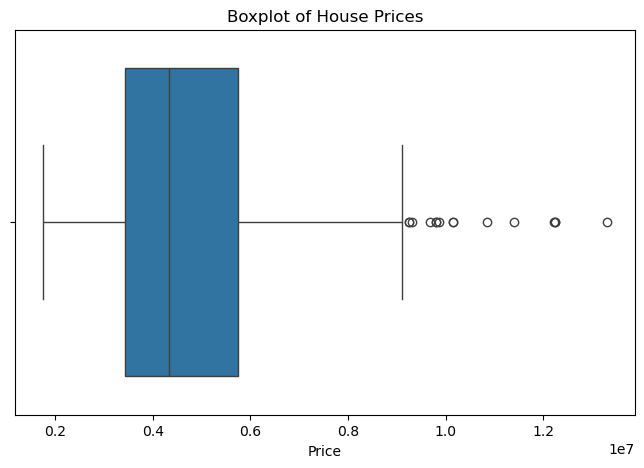

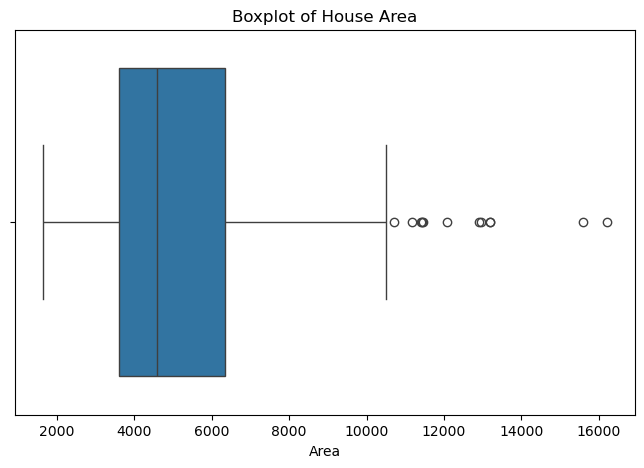

In [8]:
# Visualize outliers using boxplots

plt.figure(figsize=(8, 5))
sns.boxplot(x=df['price'])
plt.title('Boxplot of House Prices')
plt.xlabel('Price')
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(x=df['area'])
plt.title('Boxplot of House Area')
plt.xlabel('Area')
plt.show()

## Outlier Handling

Outliers were identified using the Interquartile Range (IQR) method and visualized using boxplots.

Extreme values in housing price and area were reviewed carefully. Since high-priced or large-area properties can represent legitimate housing records rather than data-entry errors, the identified outliers were retained.

This approach prevents the removal of valid observations and preserves the integrity of the original dataset.

In [9]:
# Final validation of the cleaned dataset

print("Final Dataset Shape:")
print(df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

Final Dataset Shape:
(545, 13)

Missing Values:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

Duplicate Rows:
0

Data Types:
price                int64
area                 int64
bedrooms             int64
bathrooms            int64
stories              int64
mainroad            object
guestroom           object
basement            object
hotwaterheating     object
airconditioning     object
parking              int64
prefarea            object
furnishingstatus    object
dtype: object


## Before vs After Cleaning Summary

- The dataset originally contained 545 rows and 13 columns.
- No missing values were present in the dataset.
- No duplicate records were found.
- Numerical columns were checked for invalid values and potential outliers.
- Outliers were reviewed using the IQR method and boxplots.
- Potentially valid extreme housing values were retained.
- Categorical values were standardized for consistency.
- The final dataset is clean and ready for further analysis.

In [10]:
# Save the cleaned dataset

df.to_csv("Housing_Cleaned.csv", index=False)

print("Cleaned dataset saved successfully as Housing_Cleaned.csv")

Cleaned dataset saved successfully as Housing_Cleaned.csv


## Conclusion

The housing dataset was successfully cleaned and validated.

The dataset was checked for missing values, duplicate records, incorrect data types, inconsistent categorical values, invalid numerical values, and potential outliers. Categorical values were standardized, while potential outliers were reviewed and retained where they appeared to represent valid housing observations.

The final dataset is clean, consistent, and ready for further analysis and machine learning tasks.